In [1]:
#!/usr/bin/python
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import tensorflow as tf

In [ ]:
# https://machinelearningmastery.com/learning-curves-for-diagnosing-machine-learning-model-performance/

In [2]:
try:
 device_name = os.environ['COLAB_TPU_ADDR']
 TPU_ADDRESS = 'grpc://' + device_name
 print('Found TPU at: {}'.format(TPU_ADDRESS))
except KeyError:
 print('TPU not found')

TPU not found


In [3]:
url = 'https://raw.githubusercontent.com/coledd/keras-example/master/moon_data.csv'

# Load the training data, format: x, y, label

dataset = pd.read_csv(url, error_bad_lines=False)

/usr/local/lib/python3.7/dist-packages/IPython/core/interactiveshell.py:2882: FutureWarning: The error_bad_lines argument has been deprecated and will be removed in a future version.


  exec(code_obj, self.user_global_ns, self.user_ns)


In [4]:
dataset.head()

,0.743461,0.464656,0
0,1.657557,-0.632032,1
1,-0.158789,0.255845,1
2,-1.088752,-0.396943,0
3,1.768052,-0.254432,1
4,1.954165,-0.128506,1


In [5]:
dataset.columns = ['X1', 'X2', 'Y']

class_names = ['clase_1', 'clase_2']
dataset.head()

,X1,X2,Y
0,1.657557,-0.632032,1
1,-0.158789,0.255845,1
2,-1.088752,-0.396943,0
3,1.768052,-0.254432,1
4,1.954165,-0.128506,1


In [6]:
dataset.shape

(199, 3)

In [7]:
data = dataset[['X1', 'X2']].values
labels = dataset['Y'].values

print(data.shape)
print(labels.shape)

(199, 2)
(199,)


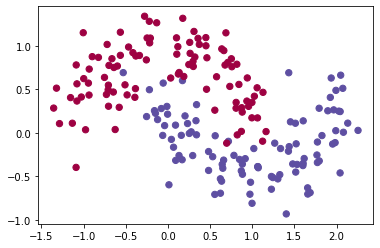

In [8]:
plt.scatter(data[:,0], data[:,1], s=40, c=labels, cmap=plt.cm.Spectral)
plt.show()

In [9]:
# Split the data into training and test data
from sklearn.model_selection import train_test_split
data_train, data_test, labels_train, labels_test = train_test_split(data, labels, test_size=0.10, random_state = 100)

In [22]:
model = tf.keras.Sequential()
model.add(tf.keras.layers.Dense(10, activation='tanh' , input_shape=(2,), name = "Capa_de_Entrada"))
model.add(tf.keras.layers.Dense(10, activation='tanh' , name = "Capa_Oculta"))
model.add(tf.keras.layers.Dense(1, activation='sigmoid', name = "Capa_de_Salida"))

model.compile(optimizer=tf.keras.optimizers.Adam(), 
              loss=tf.keras.losses.binary_crossentropy, 
                metrics=['accuracy'])

model.summary()

Model: "sequential_4"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 Capa_de_Entrada (Dense)     (None, 10)                30        
                                                                 
 Capa_Oculta (Dense)         (None, 10)                110       
                                                                 
 Capa_de_Salida (Dense)      (None, 1)                 11        
                                                                 
Total params: 151
Trainable params: 151
Non-trainable params: 0
_________________________________________________________________


dict_keys(['loss', 'accuracy', 'val_loss', 'val_accuracy'])


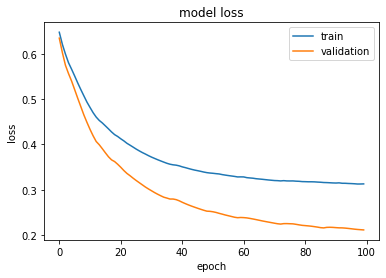

In [20]:
# Underfitting

history = model.fit(data_train, labels_train, epochs=100, verbose=0, validation_split = 0.1)
# model.summary()
print(history.history.keys())
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='upper right')
plt.show()

In [ ]:
model = tf.keras.Sequential()
model.add(tf.keras.layers.Dense(10, activation='tanh' , input_shape=(2,), name = "Capa_de_Entrada"))
model.add(tf.keras.layers.Dense(10, activation='tanh' , name = "Capa_Oculta"))
model.add(tf.keras.layers.Dense(1, activation='sigmoid', name = "Capa_de_Salida"))

model.compile(optimizer=tf.keras.optimizers.Adam(), 
              loss=tf.keras.losses.binary_crossentropy, 
                metrics=['accuracy'])

model.summary()

dict_keys(['loss', 'accuracy', 'val_loss', 'val_accuracy'])


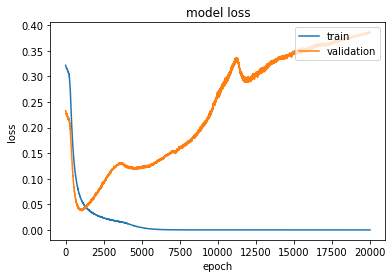

In [17]:
# Overfitting

history = model.fit(data_train, labels_train, epochs=20000, verbose=0, validation_split = 0.2)
# model.summary()
print(history.history.keys())
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='upper right')
plt.show()

In [ ]:
model = tf.keras.Sequential()
model.add(tf.keras.layers.Dense(10, activation='tanh' , input_shape=(2,), name = "Capa_de_Entrada"))
model.add(tf.keras.layers.Dense(10, activation='tanh' , name = "Capa_Oculta"))
model.add(tf.keras.layers.Dense(1, activation='sigmoid', name = "Capa_de_Salida"))

model.compile(optimizer=tf.keras.optimizers.Adam(), 
              loss=tf.keras.losses.binary_crossentropy, 
                metrics=['accuracy'])

model.summary()

dict_keys(['loss', 'accuracy', 'val_loss', 'val_accuracy'])


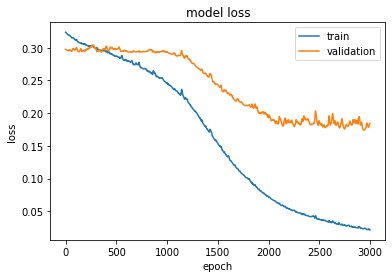

In [21]:
# Dataset de entrenamiento no representativo

history = model.fit(data_train, labels_train, epochs=3000, verbose=0, validation_split = 0.8)
# model.summary()
print(history.history.keys())
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='upper right')
plt.show()

In [ ]:
model = tf.keras.Sequential()
model.add(tf.keras.layers.Dense(10, activation='tanh' , input_shape=(2,), name = "Capa_de_Entrada"))
model.add(tf.keras.layers.Dense(10, activation='tanh' , name = "Capa_Oculta"))
model.add(tf.keras.layers.Dense(1, activation='sigmoid', name = "Capa_de_Salida"))

model.compile(optimizer=tf.keras.optimizers.Adam(), 
              loss=tf.keras.losses.binary_crossentropy, 
                metrics=['accuracy'])

model.summary()

dict_keys(['loss', 'accuracy', 'val_loss', 'val_accuracy'])


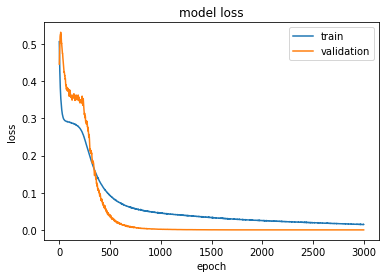

In [23]:
# Dataset de validación no representativo

history = model.fit(data_train, labels_train, epochs=3000, verbose=0, validation_split = 0.01)
# model.summary()
print(history.history.keys())
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='upper right')
plt.show()

In [25]:
model = tf.keras.Sequential()
model.add(tf.keras.layers.Dense(10, activation='tanh' , input_shape=(2,), kernel_regularizer=tf.keras.regularizers.l2(l=0.1), name = "Capa_de_Entrada"))
model.add(tf.keras.layers.Dense(10, activation='tanh' , kernel_regularizer=tf.keras.regularizers.l2(l=0.1), name = "Capa_Oculta"))
model.add(tf.keras.layers.Dense(1, activation='sigmoid', name = "Capa_de_Salida"))

model.compile(optimizer=tf.keras.optimizers.Adam(), 
              loss=tf.keras.losses.binary_crossentropy, 
                metrics=['accuracy'])

model.summary()

Model: "sequential_5"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 Capa_de_Entrada (Dense)     (None, 10)                30        
                                                                 
 Capa_Oculta (Dense)         (None, 10)                110       
                                                                 
 Capa_de_Salida (Dense)      (None, 1)                 11        
                                                                 
Total params: 151
Trainable params: 151
Non-trainable params: 0
_________________________________________________________________


dict_keys(['loss', 'accuracy', 'val_loss', 'val_accuracy'])


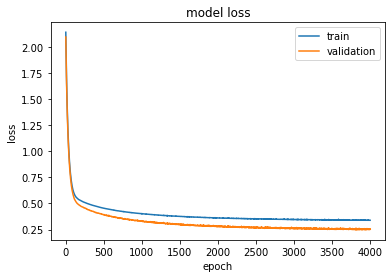

In [26]:
# Overfitting con regularización

history = model.fit(data_train, labels_train, epochs=4000, verbose=0, validation_split = 0.2)
# model.summary()
print(history.history.keys())
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='upper right')
plt.show()

In [29]:
model = tf.keras.Sequential()
model.add(tf.keras.layers.Dense(10, activation='tanh' , input_shape=(2,), name = "Capa_de_Entrada"))
model.add(tf.keras.layers.Dropout(0.2))
model.add(tf.keras.layers.Dense(10, activation='tanh' , name = "Capa_Oculta"))
model.add(tf.keras.layers.Dropout(0.2))
model.add(tf.keras.layers.Dense(1, activation='sigmoid', name = "Capa_de_Salida"))

model.compile(optimizer=tf.keras.optimizers.Adam(), 
              loss=tf.keras.losses.binary_crossentropy, 
                metrics=['accuracy'])

model.summary()

Model: "sequential_8"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 Capa_de_Entrada (Dense)     (None, 10)                30        
                                                                 
 dropout_2 (Dropout)         (None, 10)                0         
                                                                 
 Capa_Oculta (Dense)         (None, 10)                110       
                                                                 
 dropout_3 (Dropout)         (None, 10)                0         
                                                                 
 Capa_de_Salida (Dense)      (None, 1)                 11        
                                                                 
Total params: 151
Trainable params: 151
Non-trainable params: 0
_________________________________________________________________


dict_keys(['loss', 'accuracy', 'val_loss', 'val_accuracy'])


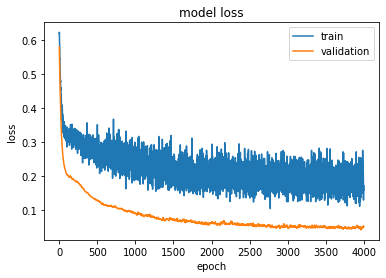

In [30]:
# Overfitting con dropout

history = model.fit(data_train, labels_train, epochs=4000, verbose=0, validation_split = 0.2)
# model.summary()
print(history.history.keys())
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='upper right')
plt.show()

In [ ]:
# Evaluar
print(model.evaluate(data, labels))
print(model.metrics_names)
predictions = model.predict(data_test)

7/7 [==============================] - 0s 2ms/step - loss: 0.0959
0.09586545825004578
['loss']


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report  

predict_label = predictions.reshape(-1).round()

print('Cantidad de predicciones = {} \n'.format(predict_label.shape))

cf_matrix = confusion_matrix(labels_test, predict_label)
print(cf_matrix)

Cantidad de predicciones = (20,) 

[[ 8  0]
 [ 1 11]]


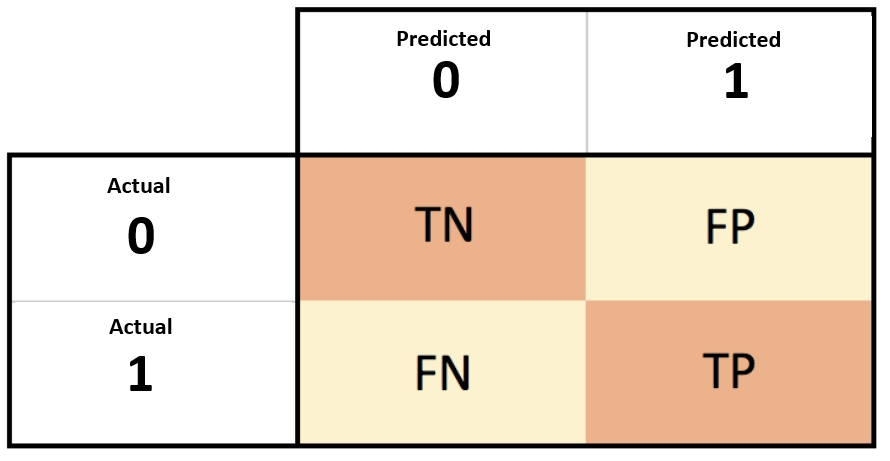

**Referencias**

*   https://enmilocalfunciona.io/deep-learning-basico-con-keras-parte-1/
*   https://github.com/coledd/keras-example
*   https://medium.com/@dtuk81/confusion-matrix-visualization-fc31e3f30fea